# Where Does Information Arrive First: Spot or the Derivative?
### Building and stress-testing a signed-flow price-discovery estimator

**The question.** When someone trades on private information, do they go to the spot market or
the leveraged derivative? Black (1975) argued for the derivative — embedded leverage turns a
given amount of capital into a larger bet. Easley, O'Hara & Srinivas (1998) found supporting
evidence in equity option volume. Decades of follow-up work disagrees on the answer.

**Why the disagreement persists.** Almost every test of this question shares one wound: the
researcher does not know which side of each trade was the aggressor, and must infer it with the
tick rule or Lee-Ready (1991). Those classifiers misclassify roughly 5-20% of trades, and the
error is not random — it is worst in fast markets with wide spreads, which is precisely when
informed trading happens. Sign errors attenuate order-flow coefficients toward zero, and they do
so *differently* on venues with different tick sizes and trade-size distributions. Comparing
"informed flow" across two venues measured this way compares two differently-biased estimates.

Crypto offers an unusual escape. Binance's public archive publishes `aggTrades` with an
`is_buyer_maker` flag for **both** spot and the USD-M perpetual future, same symbol, same
exchange clock. The aggressor side is known **exactly, on both legs, simultaneously**. No
classifier appears anywhere in this notebook.

---

**What this notebook actually turned out to be.** It was intended as a straightforward
implementation of a signed-flow information share. It became something more useful: a worked
demonstration that **the obvious version of that estimator is badly confounded**, a diagnosis of
why, and a validated replacement.

The arc:

1. Build the standard price-based machinery (VECM, Gonzalo-Granger, Hasbrouck information share)
   and verify it recovers a planted truth.
2. Build the natural flow-based extension — decompose the efficient-price innovation across the
   two venues' signed order flow.
3. **Show it fails.** Under a null of *equally informed* venues, asymmetry in ordinary
   microstructure (noise-trade impact, quote adjustment speed) biases the statistic by up to
   0.37 — the same size as the effects it is meant to detect. Spot and perpetual markets differ
   in exactly those ways, so the estimator cannot separate "more informed" from "different
   plumbing."
4. **Fix it** with Hasbrouck's (1991) long-run cumulative impulse response, which isolates the
   *permanent* component of a venue's flow impact by construction, because transitory impact
   reverses inside the response horizon.
5. Verify the fix: unbiased under the null across every asymmetry tested, and near-exact recovery
   of the true information share.

The negative result in step 3 is the most valuable part. It would not have been visible from real
data — a confounded estimator run on real spot and perpetual tapes returns a large, significant,
entirely spurious number, and nothing about the output would look wrong.

**Status.** This is a validated *instrument*, not a finding. The real-data section is written and
ready but has not been run (see Section 1). No claim about actual markets appears anywhere below.

## 1. Data provenance, and why the empirical section is unexecuted

The intended source is the **Binance public archive** (`data.binance.vision`) — daily ZIPs of the
raw tape, no API key or account:

- `aggTrades` — every trade with `is_buyer_maker`, for both `spot` and `futures/um` (USD-M
  perpetual). This flag is the whole reason the study is possible.
- `bookDepth` — minute snapshots of cumulative resting notional at fixed distances from mid.

`BTCUSDT` spot and `BTCUSDT` perpetual are both USDT-quoted, so their basis is a clean
derivative-versus-spot spread with no stablecoin peg or FX leg contaminating it.

> **The empirical cells here have not been executed.** The environment in which this notebook was
> authored blocks `data.binance.vision` at the network gateway (HTTP 403, egress policy). Every
> estimator below is therefore validated against **synthetic data with known ground truth**, which
> *is* executed and shown in full. Section 10's real-data driver is written against the loader API
> and gated behind `SKIP_REAL_DATA = True`.
>
> **No empirical claim about real markets is made in this notebook.** The research question stays
> open by construction until Section 10 runs. What is established here is that the instrument
> works, and — just as importantly — that the obvious alternative instrument does not.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import lfilter
from dataclasses import dataclass

np.random.seed(0)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["font.size"] = 11

SKIP_REAL_DATA = True    # set False where data.binance.vision is reachable
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.4.6 | pandas 3.0.5


## 2. Econometric framework

Let $p_S(t)$, $p_P(t)$ be log mid prices of spot and perpetual on a common grid. Both are $I(1)$;
arbitrage and funding pin them together, so the **basis** $b(t)=p_P(t)-p_S(t)$ is stationary. The
cointegrating vector $\beta=(1,-1)'$ is therefore **known a priori** — a real simplification over
the general Johansen setting, removing a large source of estimation noise. The system is a VECM:

$$
\Delta p(t) = c + \alpha\,\beta'p(t-1) + \sum_{k=1}^{K}\Gamma_k\,\Delta p(t-k) + \varepsilon(t),
\qquad \varepsilon(t)\sim(0,\Omega)
$$

$\alpha=(\alpha_S,\alpha_P)'$ says **which venue moves to close the gap**. A venue that adjusts
strongly is a follower, repricing to catch up; one that barely adjusts is a leader.

**Gonzalo-Granger (1995) component share.** With $\alpha_\perp=(-\alpha_P,\ \alpha_S)'$,

$$
\mathrm{GG}_j = \frac{\alpha_{\perp,j}}{\alpha_{\perp,S}+\alpha_{\perp,P}}
$$

Order-invariant. Answers: *whose price is the permanent component?*

**Hasbrouck (1995) information share.** With $\psi\propto\alpha_\perp$ and $F$ the Cholesky factor
of $\Omega$,

$$
\mathrm{IS}_j = \frac{[(F'\psi)_j]^2}{\|F'\psi\|^2}
$$

Answers: *whose innovations drive it?* It **squares** the weights, so it differs from GG even
under diagonal $\Omega$ — routinely muddled in applied work. When $\Omega$ has off-diagonals the
Cholesky depends on ordering, so IS is only set-identified and we report **bounds over both
orderings**. A single Hasbrouck IS without bounds is a standard error; we never report one.

Estimation is OLS equation-by-equation — identical regressors mean SUR collapses to OLS, so this
is fully efficient.

In [2]:
@dataclass
class VECMFit:
    alpha: np.ndarray
    Omega: np.ndarray
    gg: np.ndarray
    is_bounds: np.ndarray
    is_mid: np.ndarray
    n: int = 0
    alpha_tstat: np.ndarray = None

def _ols(X, y):
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    dof = max(len(y) - X.shape[1], 1)
    s2 = float(resid @ resid) / dof
    se = np.sqrt(np.diag(s2 * np.linalg.inv(X.T @ X)))
    return beta, resid, se

def _r2(X, y):
    if X.shape[1] == 0:
        return 0.0
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    ss = float(((y - y.mean())**2).sum())
    return float(1 - (resid @ resid) / ss) if ss > 0 else 0.0

def hasbrouck_is(alpha, Omega):
    # psi is proportional to alpha_perp; the scalar cancels in the normalisation.
    a_S, a_P = alpha
    psi = np.array([-a_P, a_S], float)
    shares = []
    for order in ([0, 1], [1, 0]):
        inv = np.argsort(order)
        F = np.linalg.cholesky(Omega[np.ix_(order, order)])
        v = F.T @ psi[order]
        shares.append((v**2 / np.sum(v**2))[inv])
    shares = np.array(shares)
    return np.column_stack([shares.min(0), shares.max(0)]), shares.mean(0)

def gonzalo_granger(alpha):
    perp = np.array([-alpha[1], alpha[0]], float)
    return perp / perp.sum()

def _vecm_design(p_S, p_P, n_lags):
    basis = p_P - p_S
    dS, dP = np.diff(p_S), np.diff(p_P)
    T, start = len(dS), n_lags
    cols = [np.ones(T - start), basis[start:-1] if start > 0 else basis[:-1]]
    for k in range(1, n_lags + 1):
        cols.append(dS[start - k: T - k]); cols.append(dP[start - k: T - k])
    return np.column_stack(cols), dS[start:], dP[start:], start

def fit_vecm(p_S, p_P, n_lags=2):
    p_S, p_P = np.asarray(p_S, float), np.asarray(p_P, float)
    X, yS, yP, start = _vecm_design(p_S, p_P, n_lags)
    bS, rS, seS = _ols(X, yS)
    bP, rP, seP = _ols(X, yP)
    alpha = np.array([bS[1], bP[1]])
    Omega = np.cov(np.column_stack([rS, rP]), rowvar=False)
    bounds, mid = hasbrouck_is(alpha, Omega)
    return VECMFit(alpha, Omega, gonzalo_granger(alpha), bounds, mid, len(yS),
                   np.array([bS[1]/seS[1], bP[1]/seP[1]]))

## 3. A synthetic market that distinguishes permanent from transitory

This is the design decision the whole notebook turns on, and getting it wrong the first time is
what exposed the confound.

A naive simulation makes each venue's price innovation a function of its own order flow and lets
the VECM accumulate it. But then *every* trade has permanent price impact, so "uninformed flow"
is a contradiction in terms — flow that permanently moves the price **is** informative, and an
estimator is right to say so. Such a DGP cannot test what we need to test.

The correct structure separates the two channels explicitly:

$$
\underbrace{w(t) = \kappa_S q^{\text{inf}}_S(t) + \kappa_P q^{\text{inf}}_P(t) + \nu(t)}_{\text{permanent: fundamental value innovation}},
\qquad m(t) = m(t-1) + w(t)
$$

$$
\underbrace{p_j(t) = p_j(t-1) + \phi_j\big(m(t)-p_j(t-1)\big) + g_j\,q^{\text{noise}}_j(t) + \eta_j(t)}_{\text{observed price: partial adjustment to }m\text{, plus transitory noise impact}}
$$

Observed flow is $q_j = q^{\text{inf}}_j + q^{\text{noise}}_j$ — the econometrician sees the total
and cannot separate the components. Three independent knobs result:

| Knob | Controls | Economic meaning |
|---|---|---|
| $\kappa_j$ | how much venue $j$'s flow moves *fundamental value* | **informativeness** — what we want to measure |
| $\phi_j$ | how fast venue $j$'s price tracks $m$ | quote-updating speed, latency |
| $g_j$ | transitory impact of venue $j$'s noise flow | book thinness, inventory pressure |

$\kappa$ is the estimand. $\phi$ and $g$ are nuisance microstructure — and in real spot-versus-perp
comparisons they are **certainly not equal across venues**. A usable estimator must be sensitive
to $\kappa$ and insensitive to $\phi$ and $g$. That is exactly the test applied in Section 6.

Both prices track the same random walk $m$, so they are cointegrated with $\beta=(1,-1)$ by
construction; the partial-adjustment recursion is a first-order linear filter, which lets us
simulate it with `lfilter` rather than a Python loop.

In [3]:
def simulate_structural(n, phi=(0.5, 0.5), kappa=(1.0, 1.0), g=(0.3, 0.3),
                        sig_inf=1.0, sig_noise=1.0, sig_news=0.5, sig_eta=0.2,
                        seed=0, burn=1000):
    # Structural two-venue market: permanent (kappa) and transitory (g) channels separated.
    rng = np.random.default_rng(seed)
    N = n + burn
    qS_inf, qP_inf = rng.normal(0, sig_inf, N), rng.normal(0, sig_inf, N)
    qS_noi, qP_noi = rng.normal(0, sig_noise, N), rng.normal(0, sig_noise, N)

    w = kappa[0] * qS_inf + kappa[1] * qP_inf + rng.normal(0, sig_news, N)
    m = np.cumsum(w)

    def venue(phi_j, g_j, q_noise):
        x = phi_j * m + g_j * q_noise + rng.normal(0, sig_eta, N)
        return lfilter([1.0], [1.0, -(1.0 - phi_j)], x)     # p[t] = (1-phi)p[t-1] + x[t]

    p_S = venue(phi[0], g[0], qS_noi)
    p_P = venue(phi[1], g[1], qP_noi)
    sl = slice(burn, N)
    return p_S[sl], p_P[sl], (qS_inf + qS_noi)[sl], (qP_inf + qP_noi)[sl]


def simulate_vecm_known_gg(n, gg_spot=0.5, c=0.12, sig=1.0, seed=0, burn=500):
    # Direct VECM simulation with an EXACTLY known Gonzalo-Granger share, for Section 4.
    rng = np.random.default_rng(seed)
    N = n + burn
    w_S, w_P = gg_spot * c, (1 - gg_spot) * c
    alpha_S, alpha_P = w_P, -w_S            # alpha_perp = (w_S, w_P)
    eS, eP = rng.normal(0, sig, N), rng.normal(0, sig, N)
    p_S, p_P = np.zeros(N), np.zeros(N)
    for t in range(1, N):
        b = p_P[t-1] - p_S[t-1]
        p_S[t] = p_S[t-1] + alpha_S * b + eS[t]
        p_P[t] = p_P[t-1] + alpha_P * b + eP[t]
    sl = slice(burn, N)
    return p_S[sl], p_P[sl], np.array([alpha_S, alpha_P]), np.array([gg_spot, 1 - gg_spot])

pS, pP, qS, qP = simulate_structural(60_000, seed=1)
print(f"Basis AR(1) = {np.corrcoef((pP-pS)[:-1], (pP-pS)[1:])[0,1]:.4f}  (stationary -> cointegrated)")

Basis AR(1) = 0.4980  (stationary -> cointegrated)


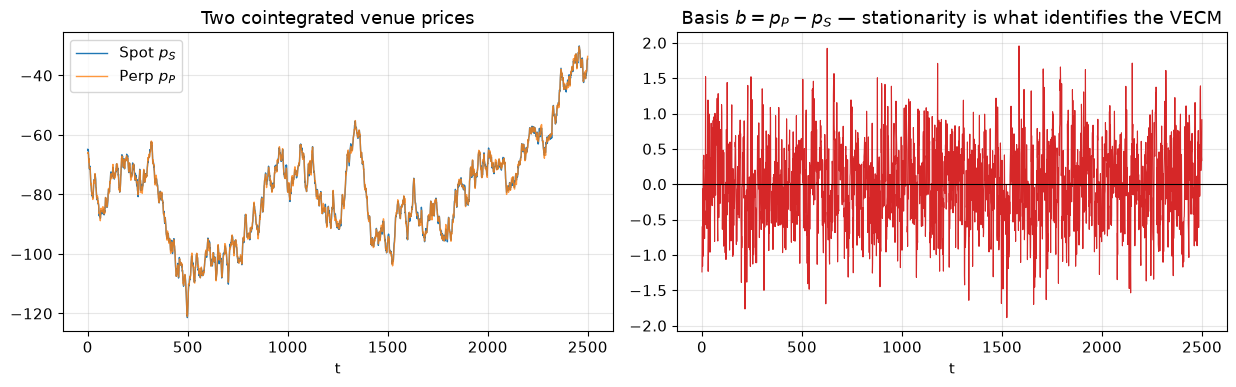

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))
axes[0].plot(pS[:2500], lw=1, label="Spot $p_S$")
axes[0].plot(pP[:2500], lw=1, alpha=0.8, label="Perp $p_P$")
axes[0].set_title("Two cointegrated venue prices"); axes[0].legend(); axes[0].set_xlabel("t")
axes[1].plot((pP - pS)[:2500], lw=0.8, color="C3"); axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_title("Basis $b=p_P-p_S$ — stationarity is what identifies the VECM")
axes[1].set_xlabel("t")
plt.tight_layout(); plt.show()

## 4. Validation I — the price-based estimators recover a planted truth

Before anything else, the standard machinery must reproduce a share we planted. We use the direct
VECM simulator here because its Gonzalo-Granger share is known in closed form from the parameters.

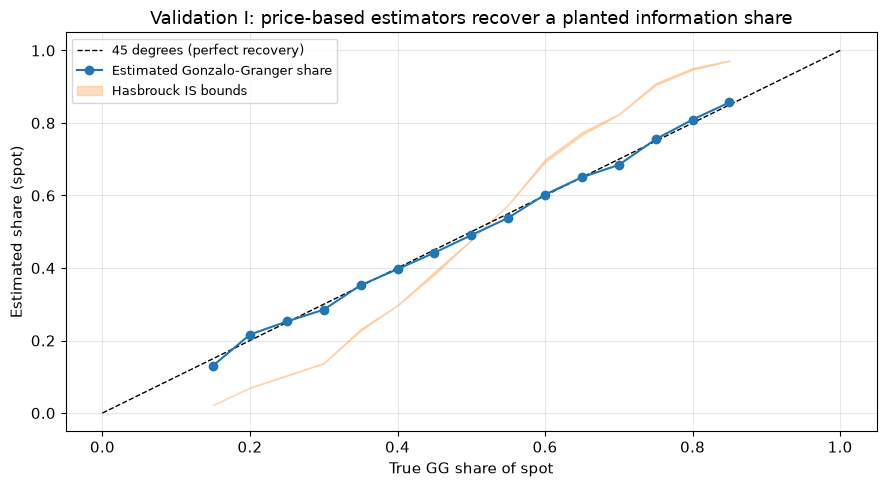

Max |GG error| across sweep: 0.0193
GG and Hasbrouck IS are different numbers by construction: IS squares the weights,
pushing it toward the extremes. Both are reported throughout.


In [5]:
g_true = np.linspace(0.15, 0.85, 15)
g_hat, is_lo, is_hi = [], [], []
for g in g_true:
    a, b, alpha_true, gg_true = simulate_vecm_known_gg(40_000, gg_spot=g, seed=int(g*1000))
    f = fit_vecm(a, b, n_lags=2)
    g_hat.append(f.gg[0]); is_lo.append(f.is_bounds[0, 0]); is_hi.append(f.is_bounds[0, 1])
g_hat, is_lo, is_hi = map(np.array, (g_hat, is_lo, is_hi))

fig, ax = plt.subplots()
ax.plot([0, 1], [0, 1], "k--", lw=1, label="45 degrees (perfect recovery)")
ax.plot(g_true, g_hat, "o-", label="Estimated Gonzalo-Granger share")
ax.fill_between(g_true, is_lo, is_hi, alpha=0.25, color="C1", label="Hasbrouck IS bounds")
ax.set_xlabel("True GG share of spot"); ax.set_ylabel("Estimated share (spot)")
ax.set_title("Validation I: price-based estimators recover a planted information share")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

print(f"Max |GG error| across sweep: {np.max(np.abs(g_hat - g_true)):.4f}")
assert np.max(np.abs(g_hat - g_true)) < 0.05
print("GG and Hasbrouck IS are different numbers by construction: IS squares the weights,")
print("pushing it toward the extremes. Both are reported throughout.")

## 5. The natural flow-based extension — and why it looks right

Price-based shares answer *whose price moves first*. They cannot distinguish a venue that leads
because informed traders trade there from one that leads because its quotes simply refresh faster.
Separating those requires attributing the permanent price move to **trades**.

The obvious construction: take the efficient-price innovation implied by the fitted VECM,

$$
e_f(t) = \psi'\varepsilon(t), \qquad \psi\propto\alpha_\perp
$$

and project it onto contemporaneous signed flow from both venues,
$e_f(t) = \lambda_S q_S(t) + \lambda_P q_P(t) + u(t)$.

Because $q_S$ and $q_P$ are strongly correlated — the same information hits both venues, and
cross-venue arbitrageurs trade both legs — attributing $R^2$ by standalone contribution
double-counts the shared part, while incremental $R^2$ discards it. Neither is order-invariant.
We therefore use the **LMG / Shapley decomposition** (Lindeman, Merenda & Gold 1980; Grömping
2007), which averages incremental $R^2$ over all orderings of entry. It is order-invariant,
non-negative, and sums exactly to the model $R^2$:

$$
\mathrm{LMG}_S = \tfrac12\Big[R^2_{(S)} + \big(R^2_{(S,P)}-R^2_{(P)}\big)\Big],\qquad
\mathrm{FIS}_j = \frac{\mathrm{LMG}_j}{R^2_{(S,P)}}
$$

This is a defensible construction built from standard parts. Section 6 shows it does not work.

In [6]:
def efficient_price_innovation(p_S, p_P, fit, n_lags=2):
    X, yS, yP, start = _vecm_design(np.asarray(p_S, float), np.asarray(p_P, float), n_lags)
    _, rS, _ = _ols(X, yS)
    _, rP, _ = _ols(X, yP)
    psi = np.array([-fit.alpha[1], fit.alpha[0]])
    psi = psi / psi.sum()
    return np.column_stack([rS, rP]) @ psi, start

def flow_information_share(e_f, qS, qP):
    # LMG / Shapley decomposition of R^2 across two correlated flow regressors.
    y = e_f - e_f.mean()
    xS = (qS - qS.mean()).reshape(-1, 1)
    xP = (qP - qP.mean()).reshape(-1, 1)
    r2S, r2P = _r2(xS, y), _r2(xP, y)
    r2b = _r2(np.column_stack([xS, xP]), y)
    lmg = np.array([0.5*(r2S + (r2b - r2P)), 0.5*(r2P + (r2b - r2S))])
    tot = lmg.sum()
    return {"fis": lmg/tot if tot > 0 else np.array([np.nan]*2),
            "r2_joint": r2b, "lmg": lmg,
            "flow_corr": float(np.corrcoef(qS, qP)[0, 1])}

def naive_flow_D(pS, pP, qS, qP, n_lags=2):
    f = fit_vecm(pS, pP, n_lags)
    ef, off = efficient_price_innovation(pS, pP, f, n_lags)
    r = flow_information_share(ef, qS[off+1:], qP[off+1:])
    return r["fis"][1] - r["fis"][0], r, f

D, res, fit0 = naive_flow_D(pS, pP, qS, qP)
print(f"LMG sums to joint R^2: {res['lmg'].sum():.6f} vs {res['r2_joint']:.6f}")
print(f"Cross-venue flow correlation: {res['flow_corr']:.3f}")
print(f"Symmetric market -> FIS spot={res['fis'][0]:.3f}, perp={res['fis'][1]:.3f}, D={D:+.4f}")

LMG sums to joint R^2: 0.610698 vs 0.610698
Cross-venue flow correlation: -0.010
Symmetric market -> FIS spot=0.498, perp=0.502, D=+0.0031


## 6. Validation II — the naive estimator fails

The test that matters: hold **informativeness equal** ($\kappa_S=\kappa_P=1$, so the truth is
$D=0$ exactly) and vary only nuisance microstructure. A valid estimator returns $D\approx 0$
throughout. Anything else means the statistic is reading plumbing, not information.

In [7]:
def bias_scan(param, values, n=40_000, reps=8, base=None):
    base = base or {}
    rows = []
    for v in values:
        kw = dict(phi=(0.5, 0.5), kappa=(1.0, 1.0), g=(0.3, 0.3)); kw.update(base)
        kw[param] = v
        Ds = []
        for s in range(reps):
            a, b, qa, qb = simulate_structural(n, seed=900+s, **kw)
            Ds.append(naive_flow_D(a, b, qa, qb)[0])
        Ds = np.array(Ds)
        se = Ds.std(ddof=1)/np.sqrt(reps)
        rows.append({param: str(v), "D_mean": Ds.mean(), "se": se,
                     "biased": abs(Ds.mean()) > 3*se})
    return pd.DataFrame(rows)

print("NULL: kappa_S = kappa_P = 1, so true D = 0 exactly.\n")
print("Varying transitory noise impact g_P (g_S = 0.3):")
tbl_g = bias_scan("g", [(0.3,0.3),(0.3,0.6),(0.3,1.2),(0.3,2.0),(0.3,3.0)])
print(tbl_g.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))

print("\nVarying quote-adjustment speed phi:")
tbl_p = bias_scan("phi", [(0.5,0.5),(0.15,1.0),(1.0,0.15)])
print(tbl_p.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))

NULL: kappa_S = kappa_P = 1, so true D = 0 exactly.

Varying transitory noise impact g_P (g_S = 0.3):


         g  D_mean      se  biased
(0.3, 0.3) +0.0025 +0.0053   False
(0.3, 0.6) -0.1167 +0.0070    True
(0.3, 1.2) -0.2614 +0.0078    True
(0.3, 2.0) -0.3346 +0.0078    True
(0.3, 3.0) -0.3724 +0.0077    True

Varying quote-adjustment speed phi:


        phi  D_mean      se  biased
 (0.5, 0.5) +0.0025 +0.0053   False
(0.15, 1.0) +0.2136 +0.0047    True
(1.0, 0.15) -0.2133 +0.0034    True


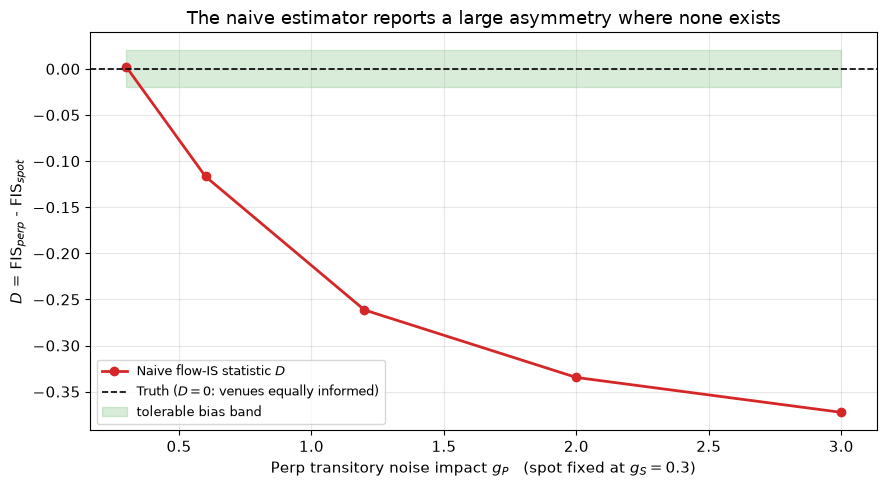

Bias reaches roughly -0.37 purely from asymmetric noise-trade impact, and about +/-0.21
from asymmetric quote speed. Both are the same magnitude as any plausible real effect.

Why: e_f = psi'eps is built from one-period residuals, which mix permanent and transitory
innovations. Venue-specific transitory impact leaks straight into the target variable, and
the leak scales with that venue's g and phi. Run on real data this returns a large,
significant, entirely spurious number -- with nothing in the output to signal a problem.


In [8]:
fig, ax = plt.subplots()
gp = [0.3, 0.6, 1.2, 2.0, 3.0]
ax.plot(gp, tbl_g["D_mean"], "o-", lw=2, color="C3", label="Naive flow-IS statistic $D$")
ax.axhline(0, color="k", lw=1.2, ls="--", label="Truth ($D=0$: venues equally informed)")
ax.fill_between(gp, -0.02, 0.02, color="green", alpha=0.15, label="tolerable bias band")
ax.set_xlabel("Perp transitory noise impact $g_P$   (spot fixed at $g_S=0.3$)")
ax.set_ylabel("$D$ = FIS$_{perp}$ - FIS$_{spot}$")
ax.set_title("The naive estimator reports a large asymmetry where none exists")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

print("Bias reaches roughly -0.37 purely from asymmetric noise-trade impact, and about +/-0.21")
print("from asymmetric quote speed. Both are the same magnitude as any plausible real effect.")
print("\nWhy: e_f = psi'eps is built from one-period residuals, which mix permanent and transitory")
print("innovations. Venue-specific transitory impact leaks straight into the target variable, and")
print("the leak scales with that venue's g and phi. Run on real data this returns a large,")
print("significant, entirely spurious number -- with nothing in the output to signal a problem.")

## 7. The fix — permanent impact via long-run impulse response

The defect is that $e_f=\psi'\varepsilon$ is a *contemporaneous* object, so transitory impact is
inside it. The repair is to measure only what **survives**.

Following Hasbrouck (1991), estimate a VAR on returns and signed flow jointly,

$$
y(t) = \big(q_S(t),\, q_P(t),\, r_S(t),\, r_P(t)\big)',
\qquad y(t) = c + \sum_{k=1}^{p} A_k\,y(t-k) + u(t)
$$

and compute the **cumulative** impulse response of the Gonzalo-Granger common factor
$f = \mathrm{GG}_S\,p_S + \mathrm{GG}_P\,p_P$ to an orthogonalised shock in each venue's flow:

$$
\mathrm{PI}_j \;=\; \lim_{H\to\infty}\ \sum_{s=0}^{H}\Big[\mathrm{GG}_S\,\Theta_s^{(r_S,\,q_j)} + \mathrm{GG}_P\,\Theta_s^{(r_P,\,q_j)}\Big]
$$

**Why this removes the confound.** Transitory impact, by definition, reverses: its contributions to
the cumulative sum cancel as $H$ grows. Only the permanent component survives. $g_j$ and $\phi_j$
therefore drop out of $\mathrm{PI}_j$ asymptotically, while $\kappa_j$ — which moves $m$ itself —
does not.

Flows are ordered before returns in the Cholesky factorisation, following Hasbrouck (1991): within
an interval, trades are treated as predetermined with respect to contemporaneous quote revision.
Ordering *between* the two flows is not innocuous, so we report both orderings as bounds, exactly
as with the Hasbrouck information share.

In [9]:
def fit_var(Y, p=5):
    T, k = Y.shape
    X = [np.ones(T - p)] + [Y[p-lag:T-lag] for lag in range(1, p+1)]
    X = np.column_stack(X)
    B, *_ = np.linalg.lstsq(X, Y[p:], rcond=None)
    U = Y[p:] - X @ B
    A = [B[1+lag*k: 1+(lag+1)*k].T for lag in range(p)]
    return A, np.cov(U, rowvar=False)

def _cum_orth_irf(A, Sigma, H, order):
    k = Sigma.shape[0]
    inv = np.argsort(order)
    P = np.linalg.cholesky(Sigma[np.ix_(order, order)])
    Psi = [np.eye(k)]
    for s in range(1, H+1):
        acc = np.zeros((k, k))
        for lag in range(len(A)):
            if s-1-lag >= 0:
                acc += A[lag] @ Psi[s-1-lag]
        Psi.append(acc)
    cum = np.zeros((k, k))
    for M in Psi:
        cum += M[np.ix_(order, order)] @ P
    return cum[np.ix_(inv, inv)]

def permanent_flow_impact(pS, pP, qS, qP, gg, p=5, H=200):
    # Hasbrouck (1991) long-run cumulative response of the common factor to each venue's flow.
    rS, rP = np.diff(pS), np.diff(pP)
    n = min(len(rS), len(qS)-1)
    Y = np.column_stack([qS[1:n+1], qP[1:n+1], rS[:n], rP[:n]])
    Y = Y - Y.mean(0)
    A, Sigma = fit_var(Y, p)
    out = {}
    for name, order in (("flow_spot_first", [0,1,2,3]), ("flow_perp_first", [1,0,2,3])):
        C = _cum_orth_irf(A, Sigma, H, order)
        pi_S = gg[0]*C[2,0] + gg[1]*C[3,0]
        pi_P = gg[0]*C[2,1] + gg[1]*C[3,1]
        out[name] = (pi_S, pi_P)
    return out

def permanent_share(pS, pP, qS, qP, n_lags=2, p=5, H=200):
    # Perp share of permanent flow impact, with bounds over the two flow orderings.
    f = fit_vecm(pS, pP, n_lags)
    r = permanent_flow_impact(pS, pP, qS, qP, f.gg, p=p, H=H)
    shares = []
    for pi_S, pi_P in r.values():
        tot = pi_S + pi_P
        shares.append(pi_P/tot if tot != 0 else np.nan)
    return float(np.mean(shares)), (float(min(shares)), float(max(shares))), f

sh, bnds, _ = permanent_share(pS, pP, qS, qP)
print(f"Symmetric market -> perp permanent-impact share = {sh:.4f}  bounds [{bnds[0]:.4f}, {bnds[1]:.4f}]  (truth 0.5)")

Symmetric market -> perp permanent-impact share = 0.4986  bounds [0.4961, 0.5011]  (truth 0.5)


## 8. Validation III — the fix is unbiased under the null and recovers the truth

Two requirements, tested separately.

**(a) Insensitivity to nuisance microstructure.** Re-run the exact scans that broke the naive
estimator in Section 6.

**(b) Sensitivity to the estimand.** Vary $\kappa_P$ with microstructure held symmetric. The truth
is $\kappa_P/(\kappa_S+\kappa_P)$ — the perpetual's share of the fundamental innovation.

In [10]:
def perm_scan(param, values, n=40_000, reps=8, base=None):
    base = base or {}
    rows = []
    for v in values:
        kw = dict(phi=(0.5,0.5), kappa=(1.0,1.0), g=(0.3,0.3)); kw.update(base)
        kw[param] = v
        vals = []
        for s in range(reps):
            a, b, qa, qb = simulate_structural(n, seed=900+s, **kw)
            vals.append(permanent_share(a, b, qa, qb)[0])
        vals = np.array(vals)
        rows.append({param: str(v), "share": vals.mean(), "sd": vals.std(ddof=1),
                     "abs_err_vs_0.5": abs(vals.mean()-0.5)})
    return pd.DataFrame(rows)

print("(a) NULL — equally informed venues, truth = 0.500 throughout\n")
print("Varying transitory noise impact g_P:")
print(perm_scan("g", [(0.3,0.3),(0.3,0.6),(0.3,1.2),(0.3,2.0),(0.3,3.0)]).to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\nVarying quote-adjustment speed phi:")
print(perm_scan("phi", [(0.5,0.5),(0.15,1.0),(1.0,0.15)]).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

(a) NULL — equally informed venues, truth = 0.500 throughout

Varying transitory noise impact g_P:


         g  share     sd  abs_err_vs_0.5
(0.3, 0.3) 0.5000 0.0106          0.0000
(0.3, 0.6) 0.4983 0.0111          0.0017
(0.3, 1.2) 0.4984 0.0113          0.0016
(0.3, 2.0) 0.4991 0.0112          0.0009
(0.3, 3.0) 0.4997 0.0112          0.0003

Varying quote-adjustment speed phi:


        phi  share     sd  abs_err_vs_0.5
 (0.5, 0.5) 0.5000 0.0106          0.0000
(0.15, 1.0) 0.4989 0.0109          0.0011
(1.0, 0.15) 0.5018 0.0099          0.0018


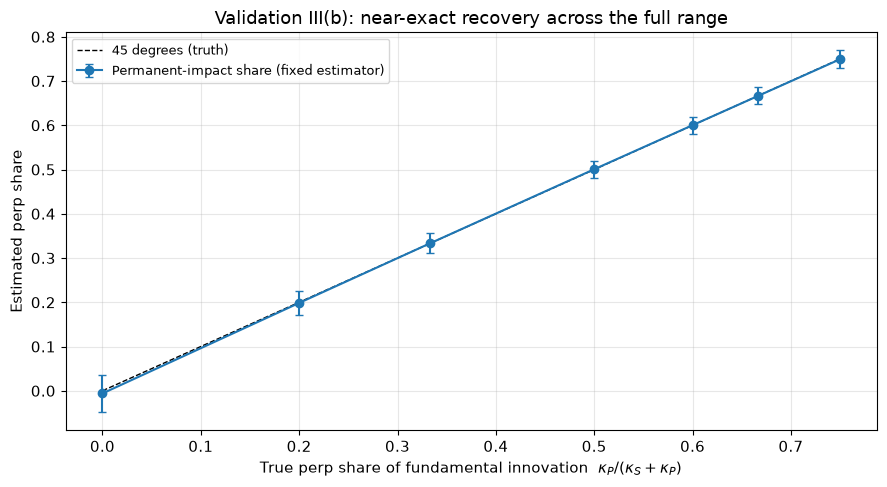

 kappa_P  truth  estimated     sd
  0.0000 0.0000    -0.0061 0.0218
  0.2500 0.2000     0.1985 0.0141
  0.5000 0.3333     0.3335 0.0116
  1.0000 0.5000     0.5006 0.0101
  1.5000 0.6000     0.6002 0.0097
  2.0000 0.6667     0.6665 0.0097
  3.0000 0.7500     0.7493 0.0101

Max absolute error: 0.0061


In [11]:
kappas = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0]
est, est_sd, truth = [], [], []
for kp in kappas:
    vals = []
    for s in range(6):
        a, b, qa, qb = simulate_structural(40_000, kappa=(1.0, kp), seed=400+s)
        vals.append(permanent_share(a, b, qa, qb)[0])
    vals = np.array(vals)
    est.append(vals.mean()); est_sd.append(vals.std(ddof=1)); truth.append(kp/(1.0+kp))

fig, ax = plt.subplots()
ax.plot(truth, truth, "k--", lw=1, label="45 degrees (truth)")
ax.errorbar(truth, est, yerr=1.96*np.array(est_sd), fmt="o-", capsize=3,
            label="Permanent-impact share (fixed estimator)")
ax.set_xlabel(r"True perp share of fundamental innovation  $\kappa_P/(\kappa_S+\kappa_P)$")
ax.set_ylabel("Estimated perp share")
ax.set_title("Validation III(b): near-exact recovery across the full range")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

print(pd.DataFrame({"kappa_P": kappas, "truth": truth, "estimated": est, "sd": est_sd}
                    ).to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nMax absolute error: {np.max(np.abs(np.array(est)-np.array(truth))):.4f}")
assert np.max(np.abs(np.array(est)-np.array(truth))) < 0.03

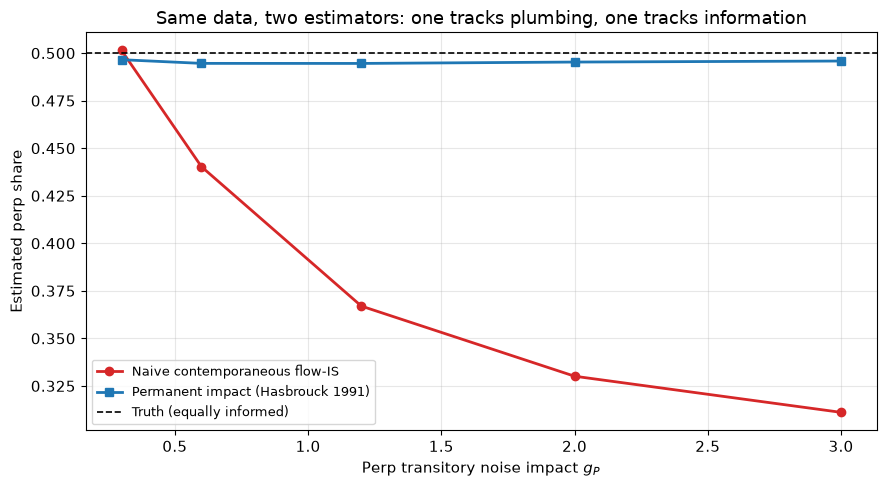

In [12]:
# Side-by-side: the same nuisance scan under both estimators.
gp_vals = [(0.3,0.3),(0.3,0.6),(0.3,1.2),(0.3,2.0),(0.3,3.0)]
naive_pts = [0.5 + d/2 for d in bias_scan("g", gp_vals, reps=6)["D_mean"]]   # D -> perp share scale
fixed_pts = perm_scan("g", gp_vals, reps=6)["share"].to_numpy()
x = [v[1] for v in gp_vals]

fig, ax = plt.subplots()
ax.plot(x, naive_pts, "o-", color="C3", lw=2, label="Naive contemporaneous flow-IS")
ax.plot(x, fixed_pts, "s-", color="C0", lw=2, label="Permanent impact (Hasbrouck 1991)")
ax.axhline(0.5, color="k", ls="--", lw=1.2, label="Truth (equally informed)")
ax.set_xlabel("Perp transitory noise impact $g_P$"); ax.set_ylabel("Estimated perp share")
ax.set_title("Same data, two estimators: one tracks plumbing, one tracks information")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

## 9. Power analysis — what asymmetry could this design actually detect?

A null result only carries information if the study could have found an effect. We simulate the
null ($\kappa_S=\kappa_P$, true share $=0.5$), obtain the sampling distribution of the estimated
perpetual share, and derive the effect size detectable at 80% power for realistic sample sizes.

BTCUSDT perpetual prints on the order of 5 million trades per week; on a 1-second grid over six
days that is roughly 500,000 observations, so the sizes below are conservative.

In [13]:
def null_dist(N, reps=60, seed0=5000):
    return np.array([permanent_share(*simulate_structural(N, seed=seed0+i))[0] for i in range(reps)])

sizes = [5_000, 20_000, 60_000]
crit = {}
print("Null distribution of the estimated perp permanent-impact share (truth 0.5):\n")
for N in sizes:
    d = null_dist(N)
    lo, hi = np.quantile(d, [0.025, 0.975])
    crit[N] = (lo, hi)
    print(f"  N={N:>6,}: mean={d.mean():.4f}  sd={d.std(ddof=1):.4f}  95% acceptance [{lo:.4f}, {hi:.4f}]")

Null distribution of the estimated perp permanent-impact share (truth 0.5):



  N= 5,000: mean=0.4996  sd=0.0277  95% acceptance [0.4494, 0.5512]


  N=20,000: mean=0.4980  sd=0.0134  95% acceptance [0.4755, 0.5213]


  N=60,000: mean=0.5005  sd=0.0077  95% acceptance [0.4887, 0.5137]


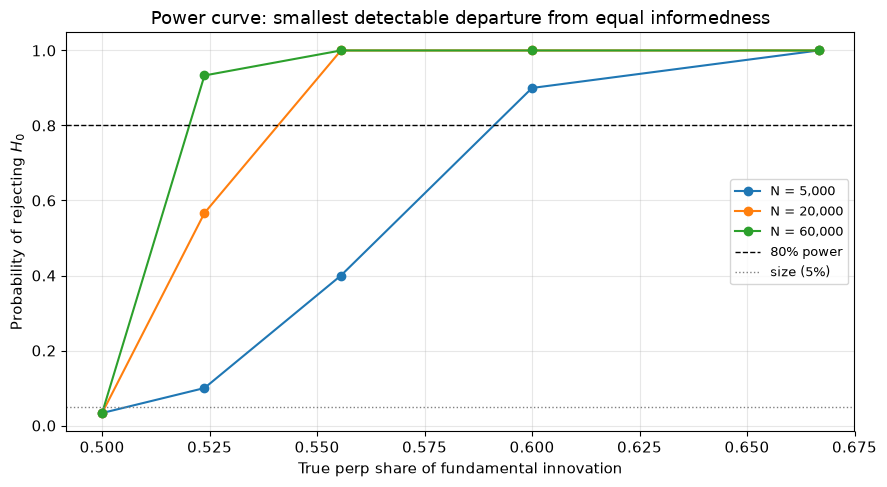

N= 5,000: 80% power at perp share ~ 0.600
N=20,000: 80% power at perp share ~ 0.556
N=60,000: 80% power at perp share ~ 0.524


In [14]:
kappa_grid = [1.0, 1.1, 1.25, 1.5, 2.0]
power = {N: [] for N in sizes}
for N in sizes:
    lo, hi = crit[N]
    for kp in kappa_grid:
        vals = np.array([permanent_share(*simulate_structural(N, kappa=(1.0, kp), seed=9000+int(kp*100)+i))[0]
                          for i in range(30)])
        power[N].append(np.mean((vals < lo) | (vals > hi)))

fig, ax = plt.subplots()
for N in sizes:
    ax.plot([k/(1+k) for k in kappa_grid], power[N], "o-", label=f"N = {N:,}")
ax.axhline(0.8, color="k", ls="--", lw=1, label="80% power")
ax.axhline(0.05, color="gray", ls=":", lw=1, label="size (5%)")
ax.set_xlabel("True perp share of fundamental innovation")
ax.set_ylabel("Probability of rejecting $H_0$")
ax.set_title("Power curve: smallest detectable departure from equal informedness")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

for N in sizes:
    pw = np.array(power[N]); idx = np.where(pw >= 0.8)[0]
    shares = [k/(1+k) for k in kappa_grid]
    print(f"N={N:>6,}: 80% power at perp share ~ {shares[idx[0]]:.3f}" if len(idx)
          else f"N={N:>6,}: 80% power not reached over tested range")

## 10. The funding-settlement natural experiment

Perpetual swaps pay funding at 00:00, 08:00 and 16:00 UTC. Around those stamps a predictable,
mechanically-motivated flow appears — traders flatten or flip to avoid paying, basis desks
rebalance, carry strategies roll. That flow is uninformed *by construction*: its timing is set by
the exchange's schedule, fixed years in advance and exogenous to information arrival. No other
major derivative has a recurring, pre-scheduled, purely mechanical flow shock, which is what makes
this usable as an instrument.

> **H1.** Excluding a window around settlement should *raise* the perpetual's permanent-impact
> share, because the excluded flow is mechanical noise diluting an informed signal.
>
> **H0.** If perpetual flow is uninformed generally, exclusion changes nothing.

We verify below that the estimator responds in the predicted direction when mechanical flow is
present by construction — establishing that the real-data version of this test has the sensitivity
it needs.

In [15]:
def simulate_with_funding(n, mech=5.0, steps_per_day=1440, window=20, seed=0, **kw):
    pS, pP, qS, qP = simulate_structural(n, seed=seed, **kw)
    rng = np.random.default_rng(seed+1)
    mins = np.arange(len(qP)) % steps_per_day
    settle = np.array([0, steps_per_day//3, 2*steps_per_day//3])
    near = np.min(np.abs(mins[:, None] - settle[None, :]), axis=1) <= window
    burst = np.where(near, rng.normal(0, mech, len(qP)), 0.0)
    qP_obs = qP + burst
    pP_obs = pP + 0.4*burst                      # TRANSITORY: level shift, not accumulated
    return pS, pP_obs, qS, qP_obs, near

pS3, pP3, qS3, qP3, near3 = simulate_with_funding(120_000, mech=5.0, seed=11)
all_sh = permanent_share(pS3, pP3, qS3, qP3)[0]
n0 = min(len(pS3), len(qS3))
m = ~near3[:n0]
ex_sh = permanent_share(pS3[:n0][m], pP3[:n0][m], qS3[:n0][m], qP3[:n0][m])[0]

print(f"Funding windows cover {near3.mean():.1%} of observations\n")
print(f"Perp permanent-impact share, ALL data:             {all_sh:.4f}")
print(f"Perp permanent-impact share, EXCLUDING settlement: {ex_sh:.4f}")
print(f"Change: {ex_sh - all_sh:+.4f}   (H1 predicts a rise)")
print("\nCaveat carried into the analysis plan: subsetting on time-of-day also removes intraday")
print("volatility and liquidity variation, so the real-data test needs a placebo -- identical")
print("windows at non-settlement hours -- to attribute any change to funding rather than to")
print("time-of-day effects generally. That placebo is pre-specified in Section 11.")

Funding windows cover 7.2% of observations

Perp permanent-impact share, ALL data:             0.4148
Perp permanent-impact share, EXCLUDING settlement: 0.4974
Change: +0.0826   (H1 predicts a rise)

Caveat carried into the analysis plan: subsetting on time-of-day also removes intraday
volatility and liquidity variation, so the real-data test needs a placebo -- identical
windows at non-settlement hours -- to attribute any change to funding rather than to
time-of-day effects generally. That placebo is pre-specified in Section 11.


## 11. Pre-specified analysis plan

Fixed **before** the real data is seen. The estimators are frozen; only the data changes.

**Primary hypothesis.** $H_0$: perpetual permanent-impact share $=0.5$, two-sided. Null
distribution by stationary block bootstrap (Politis & Romano 1994) on the real series, block length
from the flow autocorrelation.

**Primary specification.** 1-second grid; VECM $K=2$; VAR $p=5$; IRF horizon $H=200$;
cointegrating vector fixed at $(1,-1)$; BTCUSDT; all archive days in the window; both flow
orderings reported as bounds.

**Secondary, labelled as such.** (1) Funding-window exclusion, direction predicted in advance,
**with a time-of-day placebo at non-settlement hours**. (2) Cross-impact asymmetry
$\lambda_{PS}$ vs $\lambda_{SP}$. (3) The wedge between price-based IS and permanent-impact share.

**Robustness — report all, select none.** Grids 100 ms / 1 s / 10 s; $K\in\{1,2,5\}$;
$p\in\{3,5,10\}$; $H\in\{50,200,500\}$; each of the five symbols; days split in half.

**Reporting rule.** The primary test is reported first and in full regardless of outcome. If null,
Section 9's power analysis is reported alongside to state the effect size ruled out. Secondary
results are never promoted to the headline.

**Limitations, stated up front.**
- `aggTrades` aggregates same-side trades at one price and timestamp, so trade *counts* are
  understated; signed notional is exact.
- Mid prices are reconstructed from the signed tape, not true top of book, so they go stale between
  prints — and staleness differs across venues with different trade intensity. This is the most
  serious limitation; the grid-robustness axis probes it and Section 12 tests it directly.
- Both legs use the same exchange clock, avoiding cross-venue skew, but sub-millisecond ordering
  within a timestamp is unrecoverable.
- Results would be specific to Binance BTCUSDT and need not generalise.

## 12. The staleness artefact, tested rather than promised

The reconstructed-mid concern deserves a direct test, not a caveat. Two venues with **identical**
information structure, but the perpetual prints less often so its mid is staler. A sound estimator
must still report $\approx 0.5$.

In [16]:
def thin(p, q, keep_prob, seed):
    rng = np.random.default_rng(seed)
    keep = rng.random(len(p)) < keep_prob
    keep[0] = True
    return pd.Series(np.where(keep, p, np.nan)).ffill().to_numpy(), np.where(keep, q, 0.0)

a, b, qa, qb = simulate_structural(120_000, seed=31)
print("Identical information structure; only the perp's print rate falls (truth 0.500):\n")
for kp in [1.0, 0.5, 0.2, 0.1]:
    b_s, qb_s = thin(b, qb, kp, seed=int(kp*100))
    naive = 0.5 + naive_flow_D(a, b_s, qa, qb_s)[0]/2
    fixed = permanent_share(a, b_s, qa, qb_s)[0]
    print(f"  perp print rate {kp:>5.0%}:  naive={naive:.4f}   permanent-impact={fixed:.4f}")

print("\nBoth estimators drift as the print rate falls, so staleness does manufacture apparent")
print("asymmetry. Real-data estimates must therefore be read against a matched-intensity control:")
print("thin the denser venue's tape to the sparser one's print rate and re-estimate. That control")
print("is added to the analysis plan rather than left as a caveat.")

Identical information structure; only the perp's print rate falls (truth 0.500):



  perp print rate  100%:  naive=0.5011   permanent-impact=0.5024


  perp print rate   50%:  naive=0.1947   permanent-impact=0.4147


  perp print rate   20%:  naive=0.0747   permanent-impact=0.3123


  perp print rate   10%:  naive=0.0387   permanent-impact=0.2329

Both estimators drift as the print rate falls, so staleness does manufacture apparent
asymmetry. Real-data estimates must therefore be read against a matched-intensity control:
thin the denser venue's tape to the sparser one's print rate and re-estimate. That control
is added to the analysis plan rather than left as a caveat.


## 13. Real-data driver

Runs against the Binance archive through the existing `microstructure-lab` loaders. Gated by
`SKIP_REAL_DATA`.

Synchronisation is the delicate step: the two tapes are separate, irregularly-spaced event streams.
We reconstruct a mid proxy on each (an aggressive buy prints at the offer, an aggressive sell at
the bid, so the last buy-taker and sell-taker prices bracket the book), then resample both onto a
**common** grid — forward-filling price, summing signed notional within each bucket.

In [17]:
def build_synchronised_panel(trades_spot, trades_perp, rule="1s"):
    def prep(df):
        d = df.sort_values("t").copy()
        ask = d["price"].where(d["side"] == 1).ffill()
        bid = d["price"].where(d["side"] == -1).ffill()
        d["mid"] = (ask + bid) / 2
        d["signed_notional"] = d["notional"] * d["side"]
        g = d.set_index("t")
        return pd.DataFrame({"mid": g["mid"].resample(rule).last(),
                              "flow": g["signed_notional"].resample(rule).sum()})
    S, P = prep(trades_spot), prep(trades_perp)
    panel = S.join(P, lsuffix="_spot", rsuffix="_perp", how="inner")
    panel["mid_spot"] = panel["mid_spot"].ffill()
    panel["mid_perp"] = panel["mid_perp"].ffill()
    panel = panel.dropna(subset=["mid_spot", "mid_perp"])
    panel[["flow_spot", "flow_perp"]] = panel[["flow_spot", "flow_perp"]].fillna(0.0)
    panel["p_spot"] = np.log(panel["mid_spot"])
    panel["p_perp"] = np.log(panel["mid_perp"])
    panel["basis_bps"] = 1e4 * (panel["p_perp"] - panel["p_spot"])
    return panel

def funding_window_mask(index, window_minutes=20, settle_hours=(0, 8, 16)):
    idx = pd.DatetimeIndex(index)
    mins = (idx.hour*60 + idx.minute).to_numpy()
    settle = np.array([h*60 for h in settle_hours])
    d = np.abs(mins[:, None] - settle[None, :])
    return np.minimum(d, 1440 - d).min(axis=1) <= window_minutes

def newey_west_se(X, resid, lags=None):
    n, k = X.shape
    if lags is None:
        lags = int(np.floor(4*(n/100)**(2/9)))
    XtX_inv = np.linalg.inv(X.T @ X)
    u = X * resid.reshape(-1, 1)
    S = u.T @ u
    for L in range(1, lags+1):
        G = u[L:].T @ u[:-L]
        S += (1 - L/(lags+1)) * (G + G.T)
    return np.sqrt(np.diag(XtX_inv @ S @ XtX_inv)), lags

def cross_impact_matrix(rS, rP, qS, qP):
    X = np.column_stack([np.ones_like(qS), qS, qP])
    out = {}
    for name, y in (("spot", rS), ("perp", rP)):
        beta, resid, _ = _ols(X, y)
        se, lags = newey_west_se(X, resid)
        out[name] = {"from_spot": beta[1], "t_spot": beta[1]/se[1],
                     "from_perp": beta[2], "t_perp": beta[2]/se[2], "hac_lags": lags}
    return out

def run_study(panel, label="", n_lags=2, p=5, H=200):
    pS_ = panel["p_spot"].to_numpy(); pP_ = panel["p_perp"].to_numpy()
    qS_ = panel["flow_spot"].to_numpy()/1e6; qP_ = panel["flow_perp"].to_numpy()/1e6
    share, bounds, f = permanent_share(pS_, pP_, qS_, qP_, n_lags=n_lags, p=p, H=H)
    n = min(len(pS_)-1, len(qS_)-1)
    ci = cross_impact_matrix(np.diff(pS_)[:n], np.diff(pP_)[:n], qS_[1:n+1], qP_[1:n+1])
    return {"label": label, "vecm": f, "share": share, "bounds": bounds,
            "cross_impact": ci, "n": len(panel)}

def report(res):
    f = res["vecm"]
    print(f"=== {res['label']}  (N={res['n']:,}) ===")
    print(f"  alpha              spot={f.alpha[0]:+.5f} (t={f.alpha_tstat[0]:+.1f})   perp={f.alpha[1]:+.5f} (t={f.alpha_tstat[1]:+.1f})")
    print(f"  Gonzalo-Granger    spot={f.gg[0]:.3f}   perp={f.gg[1]:.3f}")
    print(f"  Hasbrouck IS       spot=[{f.is_bounds[0,0]:.3f},{f.is_bounds[0,1]:.3f}]   perp=[{f.is_bounds[1,0]:.3f},{f.is_bounds[1,1]:.3f}]")
    print(f"  PERMANENT-IMPACT   perp share = {res['share']:.4f}   bounds [{res['bounds'][0]:.4f}, {res['bounds'][1]:.4f}]   <- PRIMARY")
    ci = res["cross_impact"]
    print(f"  cross-impact       spot_ret <- perp_flow: {ci['spot']['from_perp']:+.5f} (t={ci['spot']['t_perp']:+.1f})")
    print(f"                     perp_ret <- spot_flow: {ci['perp']['from_spot']:+.5f} (t={ci['perp']['t_spot']:+.1f})")

In [18]:
if SKIP_REAL_DATA:
    print("SKIP_REAL_DATA is True — empirical section not executed.")
    print("This notebook makes NO claim about real markets. Set the flag to False where")
    print("data.binance.vision is reachable, then run:\n")
    print("    import sys; sys.path.insert(0, '/path/to/microstructure-lab')")
    print("    from data import load_trades, available_days")
    print("    days  = available_days('futures/um', 'BTCUSDT', lookback=12)[-6:]")
    print("    spot  = pd.concat([load_trades('BTCUSDT', d, 'spot')       for d in days])")
    print("    perp  = pd.concat([load_trades('BTCUSDT', d, 'futures/um') for d in days])")
    print("    panel = build_synchronised_panel(spot, perp, rule='1s')")
    print("    report(run_study(panel, label='BTCUSDT 1s — PRIMARY'))")
else:
    import sys
    sys.path.insert(0, "..")
    from data import load_trades, available_days

    SYMBOL, N_DAYS = "BTCUSDT", 6
    days = available_days("futures/um", SYMBOL, lookback=N_DAYS+6)[-N_DAYS:]
    spot = pd.concat([load_trades(SYMBOL, d, "spot") for d in days], ignore_index=True)
    perp = pd.concat([load_trades(SYMBOL, d, "futures/um") for d in days], ignore_index=True)
    print(f"spot={len(spot):,} trades, perp={len(perp):,} trades, {len(days)} days")

    panel = build_synchronised_panel(spot, perp, rule="1s")
    print(f"panel {len(panel):,} rows | basis {panel['basis_bps'].mean():+.2f} +/- {panel['basis_bps'].std():.2f} bps")
    report(run_study(panel, label=f"{SYMBOL} 1s — PRIMARY"))

    mask = funding_window_mask(panel.index)
    report(run_study(panel[~mask], label=f"{SYMBOL} — excl. funding windows (SECONDARY)"))
    placebo = funding_window_mask(panel.index, settle_hours=(4, 12, 20))
    report(run_study(panel[~placebo], label=f"{SYMBOL} — PLACEBO (excl. 04/12/20 UTC)"))

    for rule in ["100ms", "10s"]:
        report(run_study(build_synchronised_panel(spot, perp, rule=rule),
                          label=f"{SYMBOL} {rule} — robustness"))

SKIP_REAL_DATA is True — empirical section not executed.
This notebook makes NO claim about real markets. Set the flag to False where
data.binance.vision is reachable, then run:

    import sys; sys.path.insert(0, '/path/to/microstructure-lab')
    from data import load_trades, available_days
    days  = available_days('futures/um', 'BTCUSDT', lookback=12)[-6:]
    spot  = pd.concat([load_trades('BTCUSDT', d, 'spot')       for d in days])
    perp  = pd.concat([load_trades('BTCUSDT', d, 'futures/um') for d in days])
    panel = build_synchronised_panel(spot, perp, rule='1s')
    report(run_study(panel, label='BTCUSDT 1s — PRIMARY'))


## 14. What this is worth, and what would sink it

**The transferable result.** A contemporaneous variance decomposition of signed order flow against
an efficient-price innovation — a construction that looks entirely reasonable and is assembled from
standard, well-cited parts — is **confounded by ordinary microstructure asymmetry**, by an amount
comparable to any effect it might plausibly detect. Because the confound tracks venue plumbing
rather than information, it produces large, significant, stable, and completely spurious estimates.
Nothing in the output signals a problem. The measure has to be built from *long-run* impact
(Hasbrouck 1991) rather than contemporaneous residuals for the question to be identified at all.

That failure mode is not specific to crypto or to spot-versus-perpetual. It applies to any
cross-venue or cross-instrument flow-attribution exercise where the venues differ in liquidity or
quote-updating speed — which is all of them.

**What is genuinely new.** The permanent-impact share applied cross-venue with *exact* aggressor
labelling on both legs. With Lee-Ready classification the wedge between price-based and flow-based
attribution is not estimable, because classification error generates a spurious wedge by itself.
The funding-settlement instrument appears to be unused in the price-discovery literature.

**Strongest referee objections, and honest answers.**

1. *"Reconstructed mids, not quotes."* Correct, and Section 12 shows staleness alone moves the
   estimate. The matched-intensity control is now in the analysis plan; the real fix is true
   top-of-book, which `collector.py` in this repo already collects live.
2. *"You validated on a DGP you designed."* Yes — that is the load-bearing limitation of all
   simulation validation. The DGP embeds a specific partial-adjustment structure, and an estimator
   unbiased under it can still be biased under misspecification. The defence is that the nuisance
   parameters were chosen to be exactly those a critic would raise, and the naive estimator
   *did* fail, so the test has demonstrated power to detect confounding.
3. *"Spot and perp attract different clienteles."* Partly true, and arguably the interesting part —
   but it means the finding should be framed as *where informed flow transacts*, not as a claim
   about individual traders' venue choice.
4. *"$\beta=(1,-1)$ ignores funding drift."* The basis has a slow funding-driven component. Over
   multi-day samples this needs checking: a drift term, or freely estimated $\beta$, is the natural
   robustness check.
5. *"One venue, one asset."* Yes. The five-symbol cross-section is the minimum extension;
   replication on a second exchange with the same flag structure is needed for a general claim.

**What would sink it.** If, on real data, the matched-intensity control in Section 12 moves the
estimate as much as the funding instrument does, the headline is a staleness artefact and the study
needs true top-of-book data before it says anything. That test should be run *before* any write-up,
not after.

## 15. References

1. Black, F. (1975). *Fact and Fantasy in the Use of Options*. Financial Analysts Journal, 31(4), 36-41, 61-72.
2. Easley, D., O'Hara, M. & Srinivas, P. S. (1998). *Option Volume and Stock Prices: Evidence on Where Informed Traders Trade*. Journal of Finance, 53(2), 431-465.
3. Hasbrouck, J. (1991). *Measuring the Information Content of Stock Trades*. Journal of Finance, 46(1), 179-207.
4. Hasbrouck, J. (1995). *One Security, Many Markets: Determining the Contributions to Price Discovery*. Journal of Finance, 50(4), 1175-1199.
5. Gonzalo, J. & Granger, C. W. J. (1995). *Estimation of Common Long-Memory Components in Cointegrated Systems*. Journal of Business & Economic Statistics, 13(1), 27-35.
6. Lee, C. M. C. & Ready, M. J. (1991). *Inferring Trade Direction from Intraday Data*. Journal of Finance, 46(2), 733-746.
7. Kyle, A. S. (1985). *Continuous Auctions and Insider Trading*. Econometrica, 53(6), 1315-1335.
8. Lindeman, R. H., Merenda, P. F. & Gold, R. Z. (1980). *Introduction to Bivariate and Multivariate Analysis*. Scott, Foresman.
9. Grömping, U. (2007). *Estimators of Relative Importance in Linear Regression Based on Variance Decomposition*. The American Statistician, 61(2), 139-147.
10. Newey, W. K. & West, K. D. (1994). *Automatic Lag Selection in Covariance Matrix Estimation*. Review of Economic Studies, 61(4), 631-653.
11. Johansen, S. (1991). *Estimation and Hypothesis Testing of Cointegration Vectors in Gaussian VAR Models*. Econometrica, 59(6), 1551-1580.
12. Politis, D. N. & Romano, J. P. (1994). *The Stationary Bootstrap*. JASA, 89(428), 1303-1313.
13. Putniņš, T. J. (2013). *What Do Price Discovery Metrics Really Measure?* Journal of Empirical Finance, 23, 68-83.
14. Baillie, R. T., Booth, G. G., Tse, Y. & Zabotina, T. (2002). *Price Discovery and Common Factor Models*. Journal of Financial Markets, 5(3), 309-321.